In [82]:
%pip install sidetable
%conda install -c conda-forge --yes scienceplots

^C
ERROR: Operation cancelled by user
Note: you may need to restart the kernel to use updated packages.
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64

In [335]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [336]:
plt.style.use(['science','no-latex'])

In [337]:
os.getcwd()

'/home/jmuires/source/urban-mobility-simulation'

In [4]:
os.chdir("../../../")
os.getcwd()

'/Users/lenni/source/urban-mobility-simulation'

In [5]:
from simulation.helper.time import SimulationTimeConverter

In [394]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [395]:
runs = pd.read_csv("data/output/run_configs.csv")
runs = runs.sort_values(by="timestamp")
runs

,timestamp,experiment,duration_sim_min,duration_real_sec,n_vehicles,n_charging_stations,capacity_per_station,kW,seed,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
0,20240809_18:30:34,shared_charging.py,1440,332.849933,500,16,10.0,50.0,43,NaN,NaN,NaN,NaN,NaN
1,20240809_21:20:09,shared_charging.py,10080,2603.698136,500,16,5.0,22.0,43,NaN,NaN,NaN,NaN,NaN
2,20240809_22:15:47,single_infra.py,10080,574.578821,500,16,5.0,22.0,43,NaN,NaN,NaN,NaN,NaN
3,20240810_00:24:23,shared_charging.py,10080,613.348294,500,16,5.0,22.0,43,NaN,NaN,NaN,NaN,NaN
4,20240810_13:17:50,shared_charging.py,10080,1571.000000,500,12,3.0,22.0,43,NaN,NaN,NaN,NaN,NaN
5,20240810_13:18:15,single_infra.py,10080,343.000000,500,12,3.0,22.0,43,NaN,NaN,NaN,NaN,NaN
6,20240812_12:57:25,shared_charging.py,1440,1267.665039,500,12,3.0,22.0,43,0.615055,0.611137,0.370666,NaN,NaN
8,20240812_13:51:23,shared_charging.py,20160,2482.801838,500,12,3.0,22.0,43,0.596018,0.597913,0.428707,NaN,NaN
7,20240812_13:51:56,single_infra.py,20160,1603.840032,500,12,3.0,22.0,43,0.578380,0.575624,0.745821,NaN,NaN
11,20240813_08:42:53,WITS_coordinated_shared_charging.py,20160,2751.514893,500,9,4.0,22.0,43,0.330067,0.597944,0.326616,NaN,random_SOC_init


In [396]:
runs[['timestamp', 'experiment', 'service_level_fleet_0', 'service_level_fleet_1', 'avg_util_infra_0', 'avg_util_infra_1', 'notes']].tail(8)

,timestamp,experiment,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
25,20240815_15:36:03,WITS_coordinated_shared_charging.py,0.556907,0.563858,0.440716,NaN,"random_SOC_init, overbidding: (True, 0.3)"
23,20240815_15:36:16,WITS_benchmark_uncoordinated_separated.py,0.561994,0.563553,0.736498,0.736498,random_SOC_init
24,20240815_15:36:26,WITS_benchmark_uncoordinated.py,0.558994,0.559561,0.717297,NaN,random_SOC_init
26,20240815_15:37:11,WITS_coordinated_shared_charging.py,0.557707,0.563844,0.432357,NaN,"random_SOC_init, overbidding: (False, 0.3)"
27,20240815_15:37:45,WITS_coordinated_shared_charging.py,0.559302,0.562649,0.430926,NaN,", overbidding: (False, 0.3)"
28,20240815_15:38:09,WITS_coordinated_shared_charging.py,0.564148,0.562766,0.437373,NaN,", overbidding: (True, 0.3)"
29,20240815_15:39:42,WITS_benchmark_uncoordinated_separated.py,0.562206,0.559860,0.709997,0.709997,NaN
30,20240815_15:40:19,WITS_benchmark_uncoordinated.py,0.560571,0.558324,0.722539,NaN,NaN


In [397]:
RUN_UNCOORDINATED = "20240815_15:36:26"
RUN_SEPERATE = "20240815_15:36:16"
RUN_COORDINATED = "20240815_15:36:03"

In [398]:
SIM_DAYS = parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME") // 1440 + 1

## Auction

In [399]:
auction_tracking = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_auction.csv")

In [400]:
auction_tracking

,time,participant_id,location,_bids,_result
0,15,0,872664521ffffff,"[(1, 0.1307568490440855), (1, 0.18610336629899...","(1, 0.18924935961353787)"
1,15,0,872664c10ffffff,"[(1, 0.06027366624095403), (1, 0.1106160297555...","(2, 0.11061602975553789)"
2,15,0,872664c1affffff,"[(1, 0.11289529468597892), (1, 0.7882271519788...","(3, 0.11289529468597892)"
3,15,0,872664c1effffff,"[(1, 0.08937529564561555), (2, 0.7882271519788...","(3, 0.433343065574599)"
4,15,0,872664ca9ffffff,"[(1, 0.1198975524932029), (1, 0.42295314387489...","(3, 0.1198975524932029)"
...,...,...,...,...,...
5736,10005,1,872664ca9ffffff,"[(1, 0.6574639184426451)]","(1, 0.0)"
5737,10005,1,872664cacffffff,"[(1, 0.645631475279541)]","(1, 0.0)"
5738,10005,1,872664cf5ffffff,"[(1, 0.5310488797938869)]","(1, 0.0)"
5739,10005,1,872664d89ffffff,"[(1, 0.433343065574599)]","(1, 0.0)"


In [401]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_datetime))

In [402]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

In [403]:
auction_tracking[(auction_tracking['_bids.total_capacity'] - auction_tracking['_result.capacity']) <0]

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid


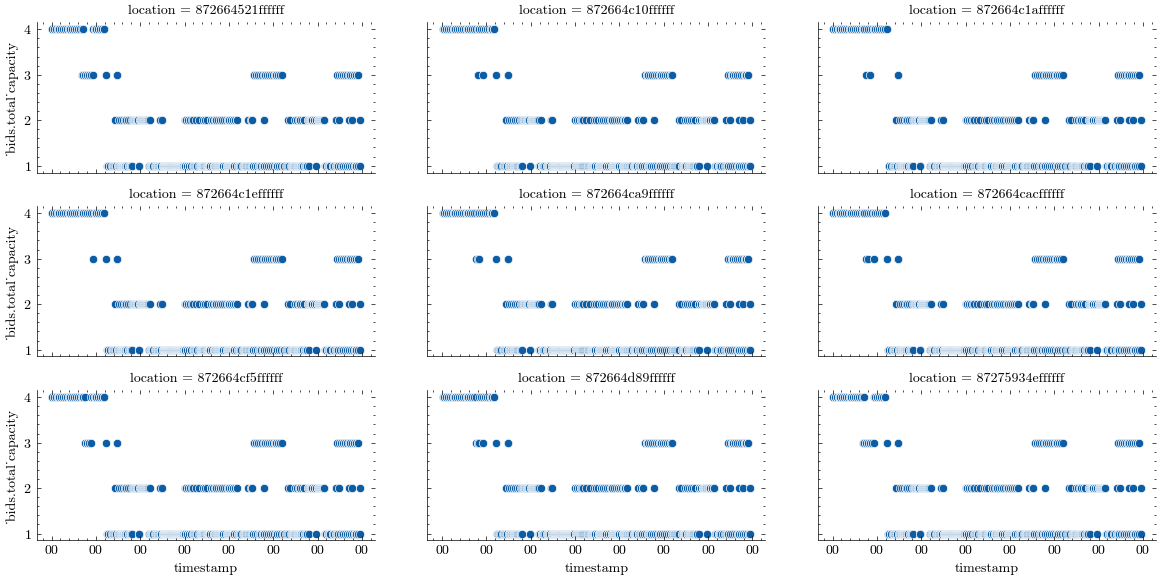

In [404]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_bids.total_capacity", col="location", col_wrap=3, kind="scatter", height=2, aspect = 2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=24))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

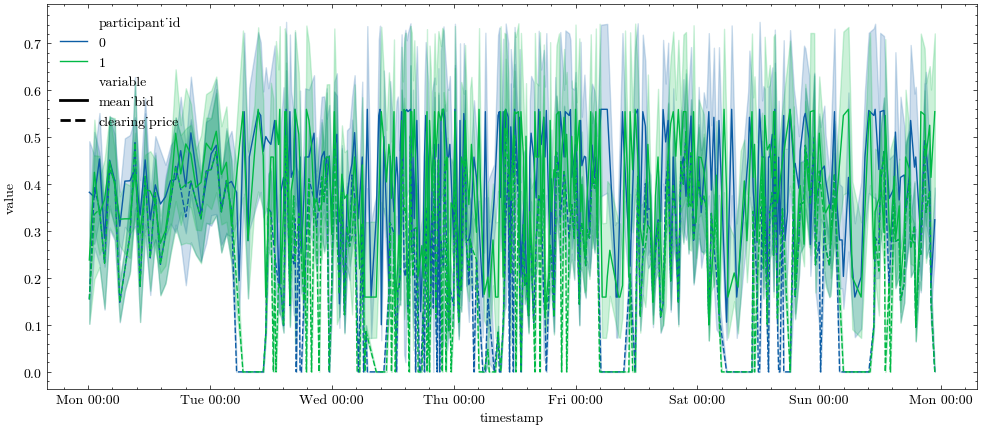

In [405]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(12,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [406]:
auction_tracking_hourly = auction_tracking.groupby('participant_id').resample('6h', on='timestamp').agg({'_bids.mean_bid': 'mean', '_result.clearing_price': 'mean'}).reset_index()

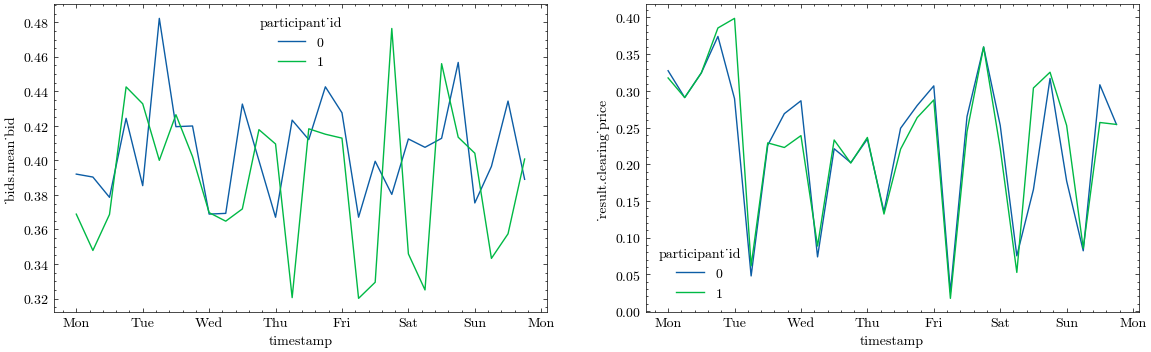

In [407]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_bids.mean_bid", hue="participant_id", ax=ax[0])
sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_result.clearing_price", hue="participant_id", ax=ax[1])

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Vehicles

In [408]:
vehicle_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_vehicles.csv")

In [409]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [410]:
# rename time axis
vehicle_tracking_coordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_coordinated['time'] = pd.to_datetime(vehicle_tracking_coordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

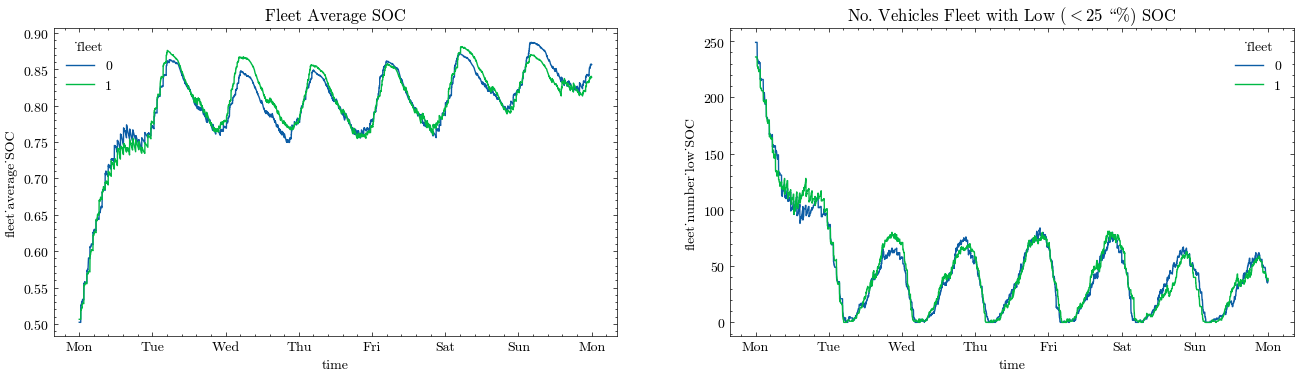

In [411]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

### with temporal varying thresholds

In [488]:
RECHARGE_THRESHOLD = [int(x) for x in parser.get("RIDE_HAILING_OPERATOR", "RECHARGE_THRESHOLD").split(",")]

# vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['hour'] = vehicle_tracking_coordinated['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

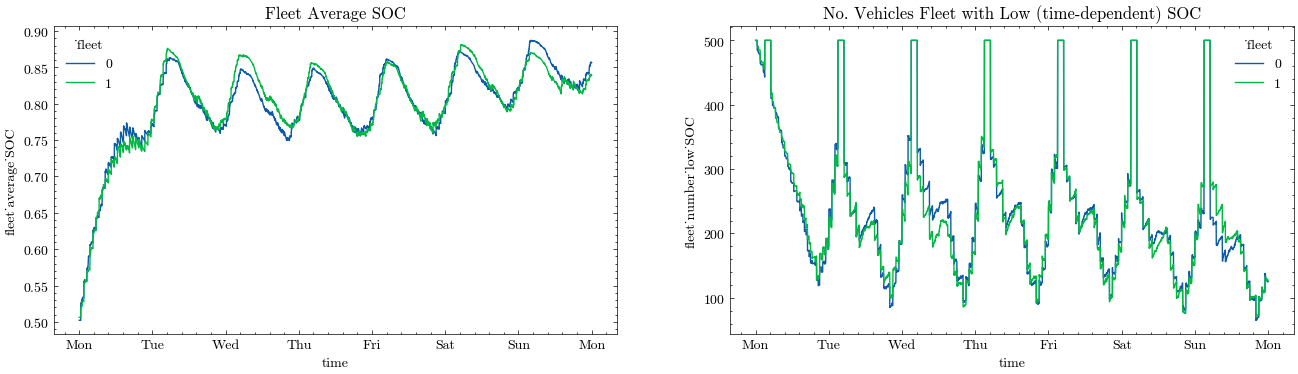

In [489]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low (time-dependent) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

### states

In [412]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [413]:
vehicle_tracking_coordinated['_state_PARKING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_coordinated['_state_CHARGING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_coordinated['_state_DRIVING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_coordinated['_state_RELOCATING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_coordinated['_state_PRE_SERVICE'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_coordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_coordinated['_state_RESERVED'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

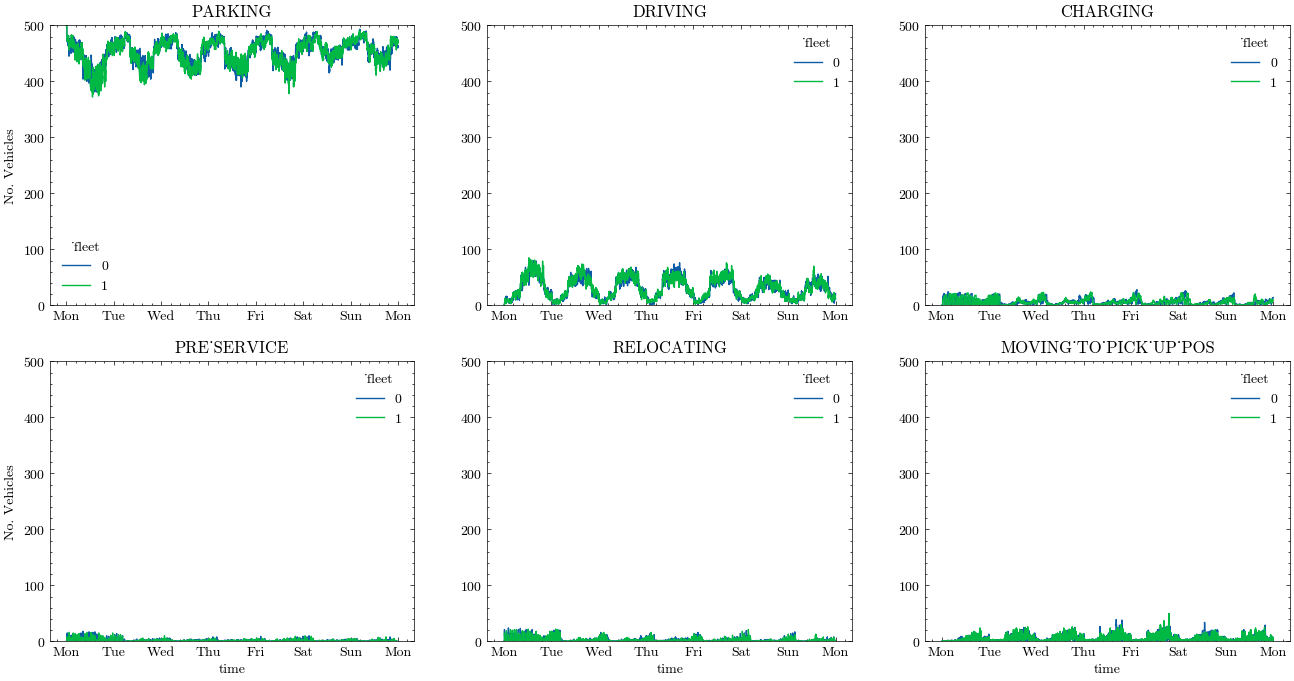

In [414]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [415]:
charging_station_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_charging_stations.csv")

In [416]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [417]:
charging_station_tracking_coordinated['utilization'] = charging_station_tracking_coordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking_coordinated['system_wide_utilization'] = charging_station_tracking_coordinated.groupby('time')['utilization'].transform('mean')

In [418]:
# rename time axis
charging_station_tracking_coordinated['time'] = pd.to_datetime(charging_station_tracking_coordinated['time'].apply(SimulationTimeConverter.as_datetime))

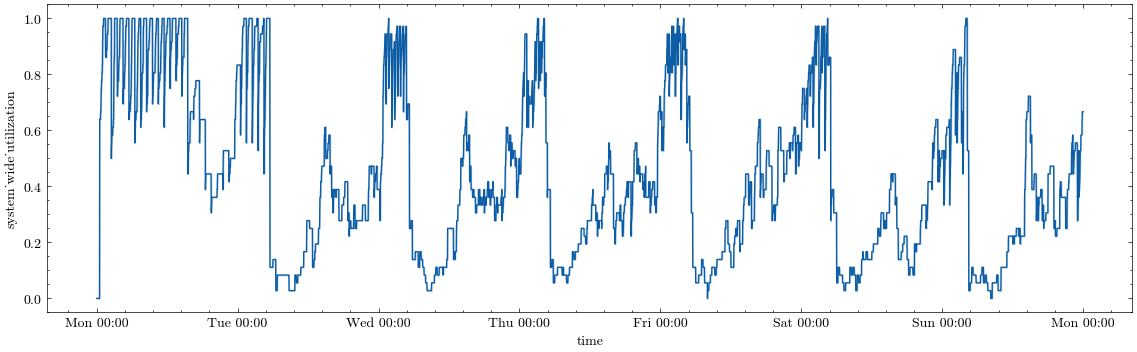

In [419]:
fig, ax = plt.subplots(1,1, figsize=(14,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

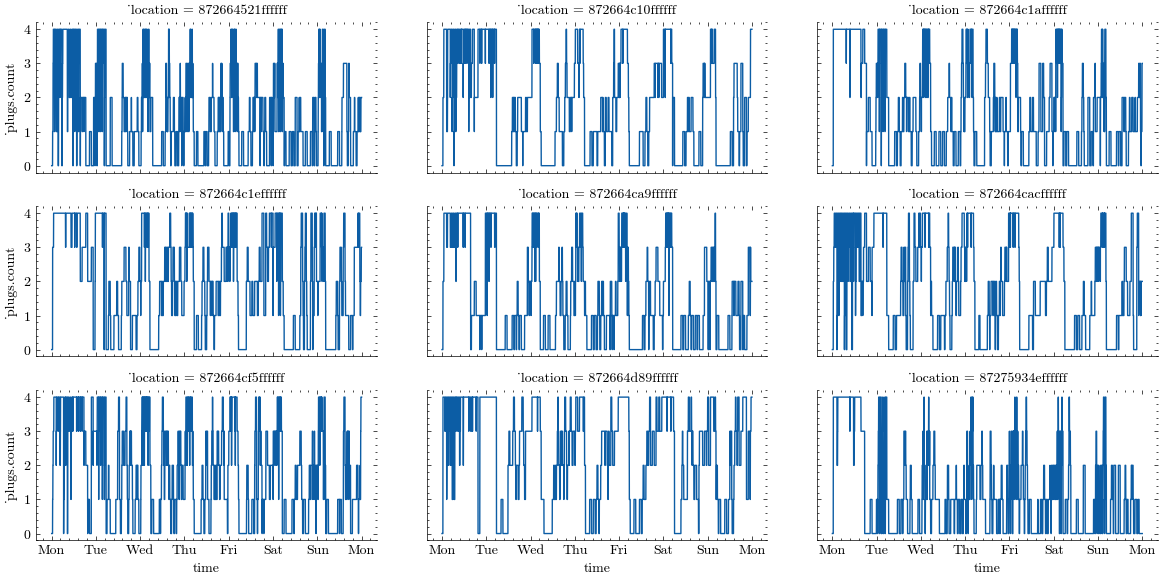

In [420]:
charging_station_tracking_coordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_coordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [ ]:
# fig, ax = plt.subplots(1,1, figsize=(8,4))

# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.count', label='util', ax=ax)
# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.queuesize', label='queue size', ax=ax)

# ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

## Transactions

In [423]:
transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_transactions.csv")

In [424]:
RESAMPLE_RATE = '1h'

In [425]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'])
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'])
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [426]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
# transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
# transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

# transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
# transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [427]:
transactions_fleet_0_resampled

state                    
state               Fulfilled    MISSED   REFUSED
timestamp                                        
2024-01-01 00:00:00  0.432432       NaN  0.567568
2024-01-01 01:00:00  0.576271       NaN  0.423729
2024-01-01 02:00:00  0.512195       NaN  0.487805
2024-01-01 03:00:00  0.565217       NaN  0.434783
2024-01-01 04:00:00  0.542169       NaN  0.457831
...                       ...       ...       ...
2024-01-07 19:00:00  0.508333  0.208333  0.283333
2024-01-07 20:00:00  0.569620  0.219409  0.210970
2024-01-07 21:00:00  0.458824  0.329412  0.211765
2024-01-07 22:00:00  0.365169  0.382022  0.252809
2024-01-07 23:00:00  0.355556  0.350000  0.294444

[168 rows x 3 columns]

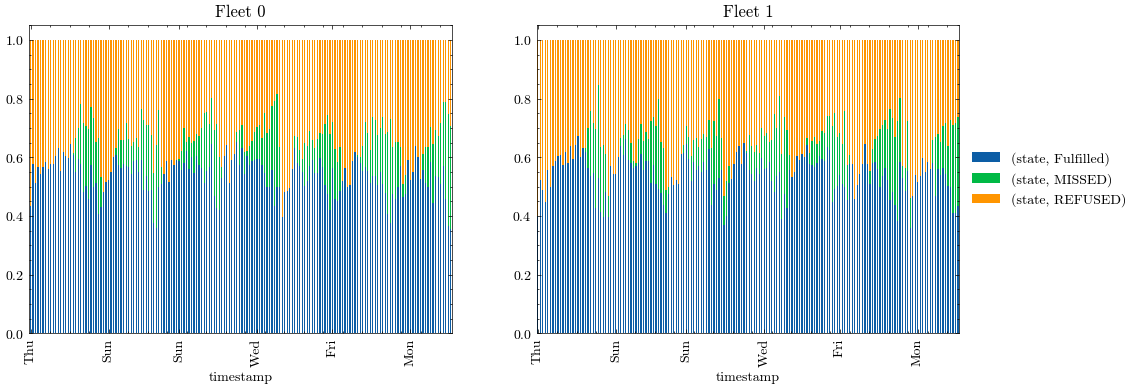

In [428]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

(0.0, 1.0)

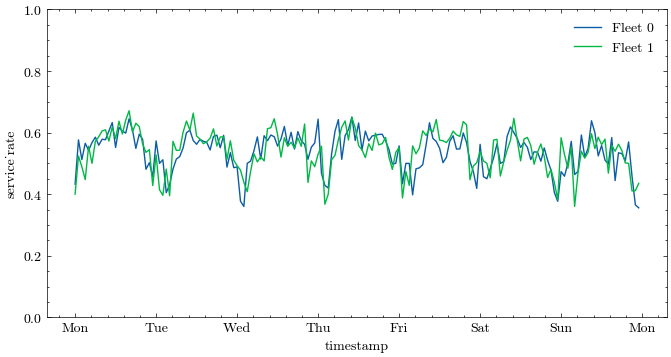

In [429]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [430]:
vehicle_tracking_coordinated['fleet_vdt'] = vehicle_tracking_coordinated['_vdt'].apply(lambda x: sum(eval(x)))

In [431]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [432]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

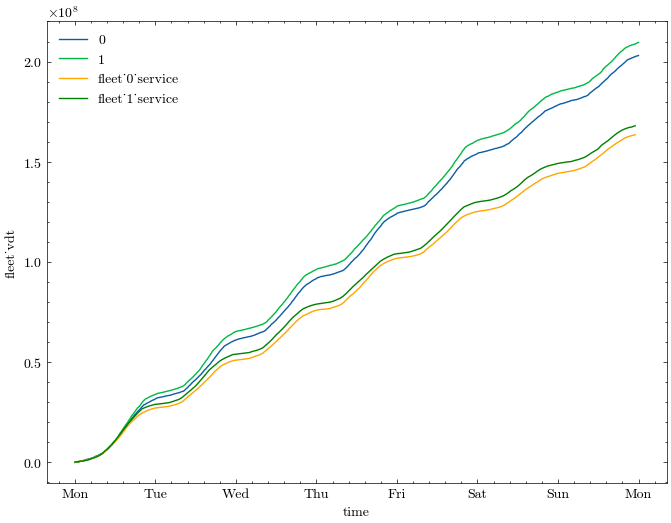

In [433]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [434]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking_coordinated.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [435]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [436]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [437]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [438]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
2024-01-01 00:00:00,1.591959e+05,2.215807e+05,76285.509448,7.628551e+04,130913.534057,1.309135e+05,0.520807,0.409184,159195.871617,221580.700885
2024-01-01 01:00:00,7.441989e+05,6.092032e+05,407144.622199,4.834301e+05,225300.535514,3.562141e+05,0.304030,0.418763,585002.979797,387622.502817
2024-01-01 02:00:00,1.172743e+06,9.639247e+05,249014.788900,7.324449e+05,276936.261715,6.331503e+05,0.418929,0.219285,428544.367532,354721.454655
2024-01-01 03:00:00,1.673081e+06,1.360403e+06,272486.491895,1.004931e+06,221838.302765,8.549886e+05,0.455395,0.440478,500337.910800,396478.178479
2024-01-01 04:00:00,2.123354e+06,1.864197e+06,329305.665988,1.334237e+06,379272.010295,1.234261e+06,0.268653,0.247169,450272.766404,503794.286070


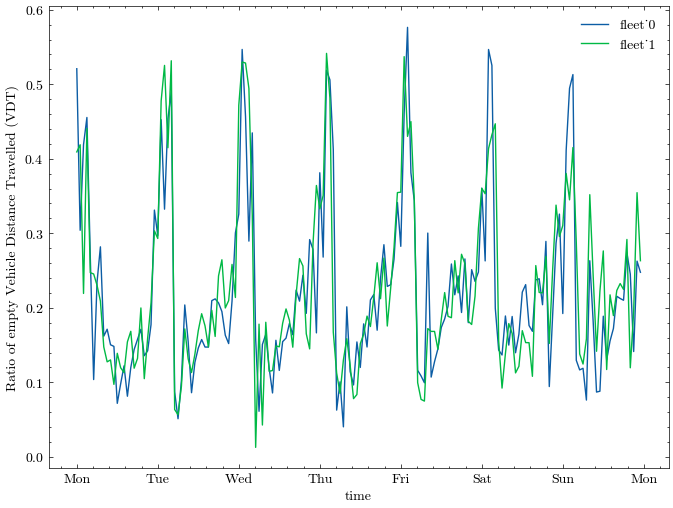

In [439]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Service Tasks

In [440]:
task_transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_task_transactions.csv")

In [441]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'])

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'])

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [442]:
task_transactions_fleet_0

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,16,30,89.999999,444,TaskState.FINISHED,0,87275934effffff,13.373626,59.999999,22.000000,2024-01-01 00:16:00,73.999999
1,16,30,89.999999,140,TaskState.FINISHED,0,872664c1effffff,13.249374,59.999999,22.000000,2024-01-01 00:16:00,73.999999
2,16,30,89.999999,96,TaskState.FINISHED,0,872664c1affffff,12.751049,59.999999,22.000000,2024-01-01 00:16:00,73.999999
3,16,30,89.999999,107,TaskState.FINISHED,0,872664c1affffff,12.725698,59.999999,22.000000,2024-01-01 00:16:00,73.999999
4,16,30,89.999999,88,TaskState.FINISHED,0,872664c1affffff,12.619677,59.999999,22.000000,2024-01-01 00:16:00,73.999999
...,...,...,...,...,...,...,...,...,...,...,...,...
1427,10036,10020,10079.999999,99,TaskState.FINISHED,0,872664d89ffffff,-27.165317,32.834682,12.039383,2024-01-07 23:16:00,43.999999
1428,10036,10020,10079.999999,389,TaskState.FINISHED,0,872664cf5ffffff,-27.274660,32.725339,11.999291,2024-01-07 23:16:00,43.999999
1429,10051,10020,10079.999999,84,TaskState.FINISHED,0,872664521ffffff,-35.051316,24.948683,9.147850,2024-01-07 23:31:00,28.999999
1430,10036,10020,10079.999999,312,TaskState.FINISHED,0,872664cf5ffffff,-35.272883,24.727116,9.066609,2024-01-07 23:16:00,43.999999


In [443]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                    
TaskState.FINISHED           1431
TaskState.MISSED_TIMESLOT       1
Name: count, dtype: int64

state                    
TaskState.FINISHED           1458
TaskState.MISSED_TIMESLOT       1
Name: count, dtype: int64

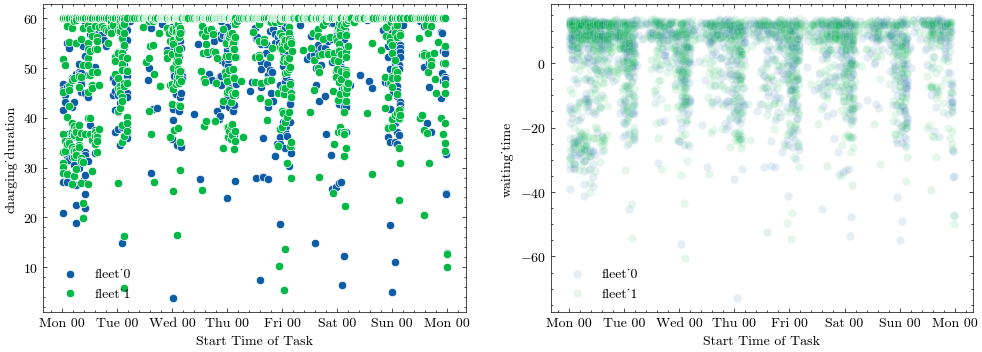

In [446]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1], alpha=.1)
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1], alpha=.1)

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

<Axes: xlabel='waiting_time', ylabel='Density'>

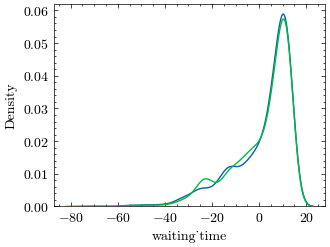

In [469]:
sns.kdeplot(data=task_transactions_fleet_0, x='waiting_time', label='fleet_0')
sns.kdeplot(data=task_transactions_fleet_1, x='waiting_time', label='fleet_1')

In [447]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

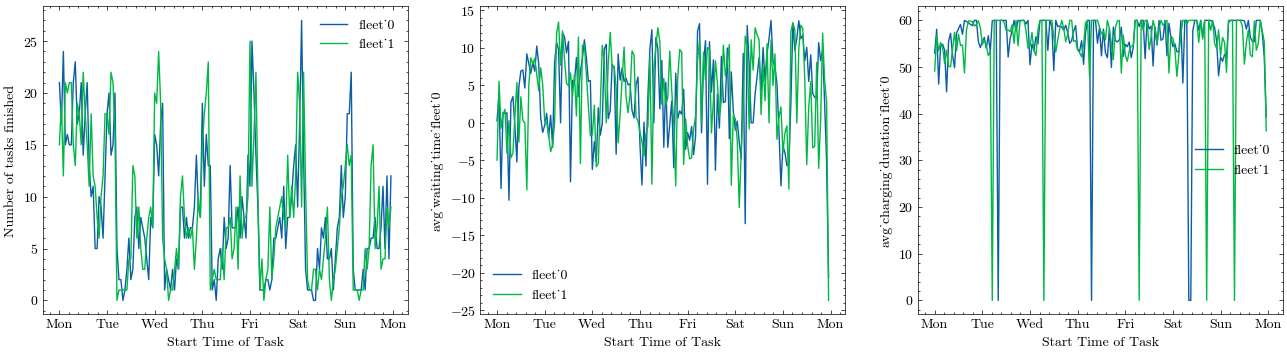

In [448]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS + 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [449]:
date_range = range(0,parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME"), 15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [450]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_datetime)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'])

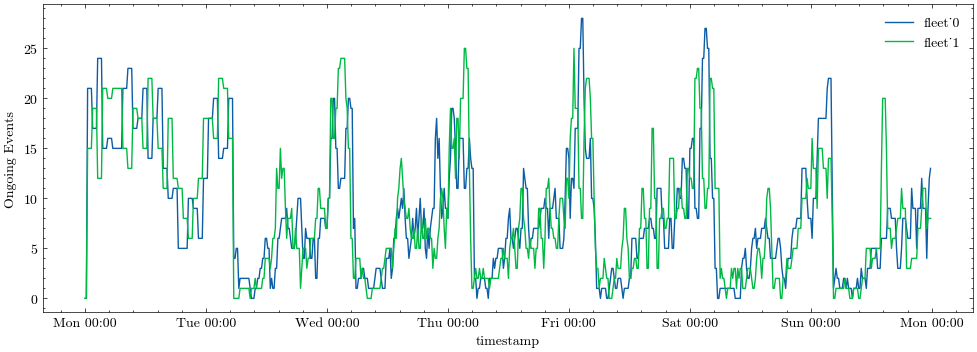

In [451]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


In [452]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [453]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [454]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [455]:
tasks_incl_price.head()

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,16,30,89.999999,444,TaskState.FINISHED,0,87275934effffff,13.373626,59.999999,22.0,2024-01-01 00:16:00,73.999999,30.0,NaN,NaN,9.46
1,16,30,89.999999,140,TaskState.FINISHED,0,872664c1effffff,13.249374,59.999999,22.0,2024-01-01 00:16:00,73.999999,30.0,NaN,NaN,9.46
2,16,30,89.999999,96,TaskState.FINISHED,0,872664c1affffff,12.751049,59.999999,22.0,2024-01-01 00:16:00,73.999999,30.0,NaN,NaN,9.46
3,16,30,89.999999,107,TaskState.FINISHED,0,872664c1affffff,12.725698,59.999999,22.0,2024-01-01 00:16:00,73.999999,30.0,NaN,NaN,9.46
4,16,30,89.999999,88,TaskState.FINISHED,0,872664c1affffff,12.619677,59.999999,22.0,2024-01-01 00:16:00,73.999999,30.0,NaN,NaN,9.46


In [456]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

/home/jmuires/anaconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from font(s) cmr10.
  func(*args, **kwargs)
/home/jmuires/anaconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


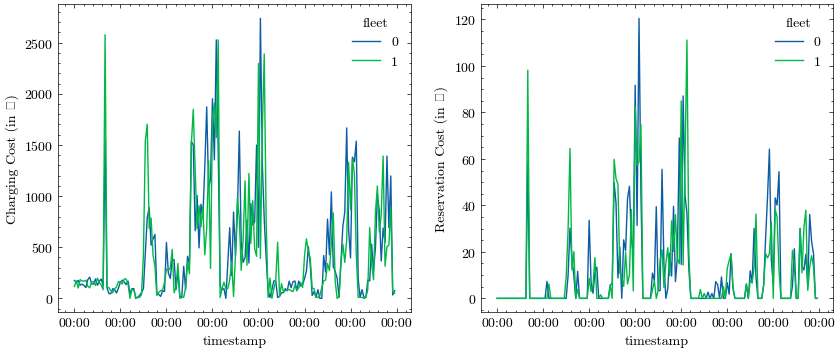

In [457]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmarks: Single Infrastructure, No Coordination // Seperate Infrastructures

In [458]:
charging_station_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_charging_stations.csv")
vehicle_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_vehicles.csv")

charging_station_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_charging_stations.csv")
vehicle_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_vehicles.csv")

In [459]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_uncoordinated['fleet_average_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_uncoordinated['fleet_number_low_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

vehicle_tracking_seperate['fleet_average_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_seperate['fleet_number_low_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [460]:
# rename time axis
vehicle_tracking_uncoordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_uncoordinated['time'] = pd.to_datetime(vehicle_tracking_uncoordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

vehicle_tracking_seperate.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_seperate['time'] = pd.to_datetime(vehicle_tracking_seperate['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

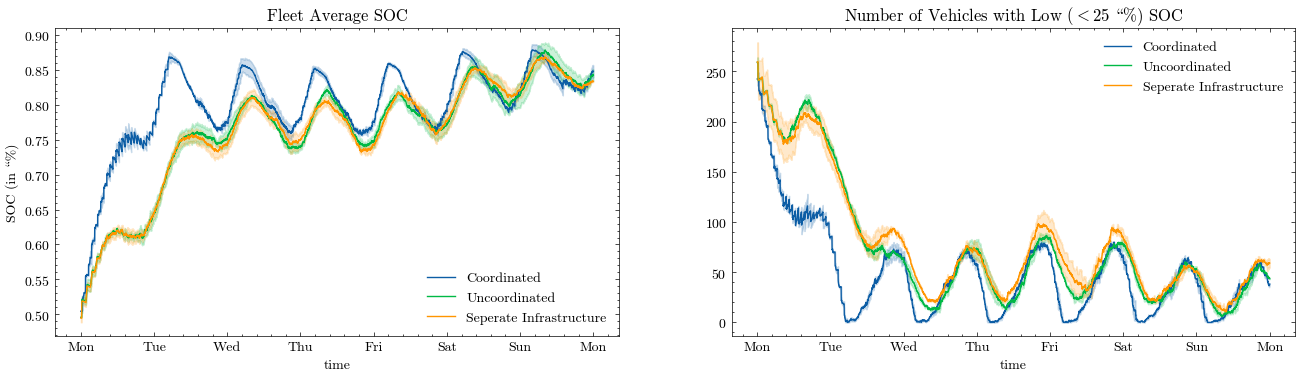

In [461]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_average_SOC', ax = ax[0], label='Seperate Infrastructure')

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Seperate Infrastructure')

ax[0].set_title('Fleet Average SOC')
ax[0].set_ylabel('SOC (in \%)')
ax[1].set_title(f'Number of Vehicles with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')
ax[1].set_ylabel('')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

In [462]:
charging_station_tracking_uncoordinated['utilization'] = charging_station_tracking_uncoordinated['_plugs.count'] / CHARGING_STATION_CAPACITY
charging_station_tracking_uncoordinated['system_wide_utilization'] = charging_station_tracking_uncoordinated.groupby('time')['utilization'].transform('mean')

charging_station_tracking_seperate['utilization'] = charging_station_tracking_seperate['_plugs.count'] / (CHARGING_STATION_CAPACITY / 2)
charging_station_tracking_seperate['system_wide_utilization'] = charging_station_tracking_seperate.groupby('time')['utilization'].transform('mean')

In [463]:
# rename time axis
charging_station_tracking_uncoordinated['time'] = pd.to_datetime(charging_station_tracking_uncoordinated['time'].apply(SimulationTimeConverter.as_datetime))
charging_station_tracking_seperate['time'] = pd.to_datetime(charging_station_tracking_seperate['time'].apply(SimulationTimeConverter.as_datetime))

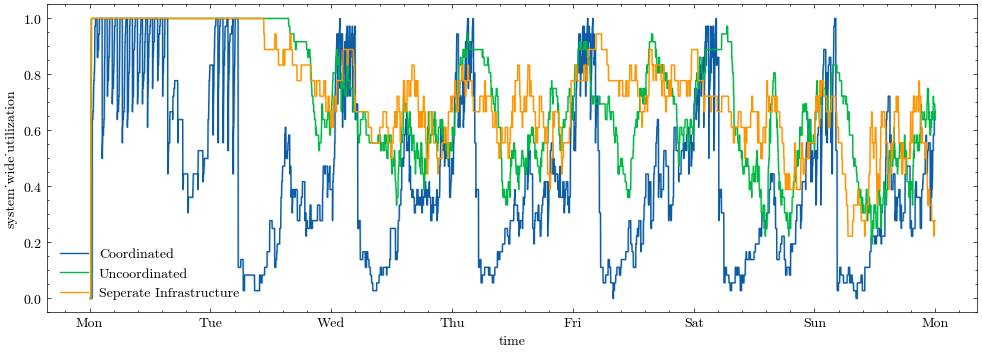

In [464]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', label= 'Coordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_uncoordinated, x='time', y='system_wide_utilization', label= 'Uncoordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_seperate, x='time', y='system_wide_utilization', label= 'Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [465]:
transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_transactions.csv")

transactions_fleet_0_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_0_transactions.csv")
transactions_fleet_1_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_1_transactions.csv")

In [466]:
transactions_fleet_0_uncoordinated['timestamp'] = transactions_fleet_0_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_0_uncoordinated['timestamp'])
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_uncoordinated['timestamp'] = transactions_fleet_1_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_1_uncoordinated['timestamp'])
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_0_seperate['timestamp'] = transactions_fleet_0_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_seperate['timestamp'] = pd.to_datetime(transactions_fleet_0_seperate['timestamp'])
transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_seperate['timestamp'] = transactions_fleet_1_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_seperate['timestamp'] = pd.to_datetime(transactions_fleet_1_seperate['timestamp'])
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()


# normalize
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated_resampled.div(transactions_fleet_0_uncoordinated_resampled.sum(axis=1), axis=0)
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated_resampled.div(transactions_fleet_1_uncoordinated_resampled.sum(axis=1), axis=0)

transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate_resampled.div(transactions_fleet_0_seperate_resampled.sum(axis=1), axis=0)
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate_resampled.div(transactions_fleet_1_seperate_resampled.sum(axis=1), axis=0)

# calc service rate, per fleet and overall
transactions_fleet_0_uncoordinated_resampled['service_rate'] = transactions_fleet_0_uncoordinated_resampled[('state', 'Fulfilled')]
transactions_fleet_1_uncoordinated_resampled['service_rate'] = transactions_fleet_1_uncoordinated_resampled[('state', 'Fulfilled')]

transactions_fleet_0_seperate_resampled['service_rate'] = transactions_fleet_0_seperate_resampled[('state', 'Fulfilled')]
transactions_fleet_1_seperate_resampled['service_rate'] = transactions_fleet_1_seperate_resampled[('state', 'Fulfilled')]

service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_seperate_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

service_rate_coordinated['service_rate'] = service_rate_coordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_uncoordinated['service_rate'] = service_rate_uncoordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_seperate['service_rate'] = service_rate_seperate[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)

/tmp/ipykernel_23177/2214906733.py:32: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_23177/2214906733.py:33: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_23177/2214906733.py:34: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merg

(0.0, 1.0)

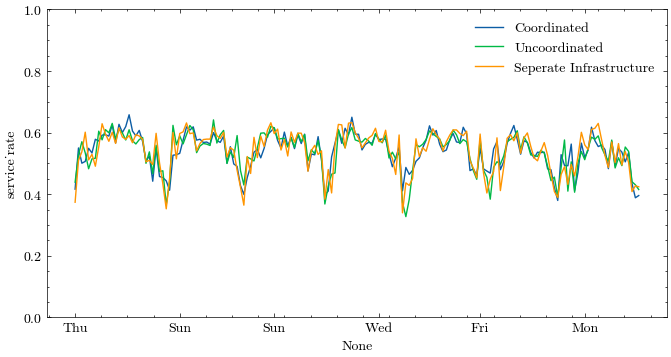

In [467]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

sns.lineplot(data=service_rate_coordinated, x = service_rate_coordinated.index, y = 'service_rate', label='Coordinated', ax=ax)
sns.lineplot(data=service_rate_uncoordinated, x = service_rate_uncoordinated.index, y = 'service_rate', label='Uncoordinated', ax=ax)
sns.lineplot(data=service_rate_seperate, x = service_rate_seperate.index, y = 'service_rate', label='Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

In [471]:
service_rate_coordinated['service_rate'].describe()

count    168.000000
mean       0.539522
std        0.058985
min        0.379582
25%        0.503805
50%        0.550070
75%        0.578343
max        0.657840
Name: service_rate, dtype: float64

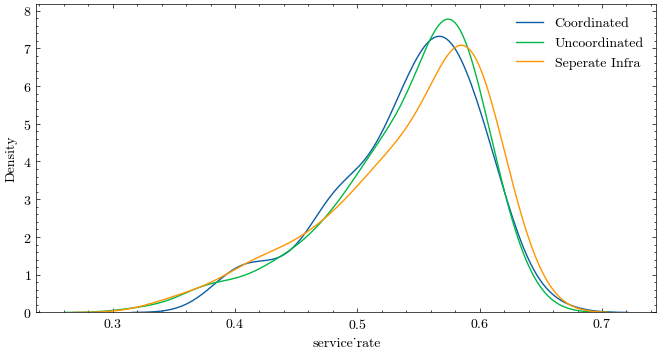

In [479]:
fig, ax = plt.subplots(1,1, figsize=(8,4))

sns.kdeplot(data = service_rate_coordinated, x='service_rate', label='Coordinated', ax=ax)
sns.kdeplot(data = service_rate_uncoordinated, x='service_rate', label='Uncoordinated', ax=ax)
sns.kdeplot(data = service_rate_seperate, x='service_rate', label='Seperate Infra', ax=ax)

ax.legend()

### compare one day with Anthony's results

In [ ]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

In [ ]:
benchmark_no_coordination

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [ ]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

In [ ]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS +  1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

NameError: name 'benchmark_no_coordination' is not defined

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

NameError: name 'vehicle_tracking' is not defined

Error in callback <function _draw_all_if_interactive at 0x11a52d670> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 1000x400 with 2 Axes>

In [ ]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


NameError: name 'hourly_tasks' is not defined

Error in callback <function _draw_all_if_interactive at 0x11a52d670> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 1000x400 with 2 Axes>

In [ ]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [ ]:
metrics_no_coordination

In [ ]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

In [ ]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

### other stuff

In [ ]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [ ]:
transactions_fleet_0['pick_up_time'].describe()